# Quantum Paldus transform

Spin-free Hamiltonians, such as the molecular electronic Hamiltonian without spin-orbit coupling or the Fermi-Hubbard model, conserve the particle number $N$, the total spin $S$, and the spin projection $M$. In the occupation number basis, these quantum numbers are spread across the amplitudes of a state, so you can't read off or control on the total spin of a state directly. The **quantum Paldus transform** ([arXiv:2506.09151](https://arxiv.org/abs/2506.09151)) is a change of basis that stores each of them in its own register:

$$
U_P \left( |0\rangle_N |0\rangle_S |0\rangle_M \otimes |N, S, M; \mathbf{d}\rangle \right)
= |N\rangle_N |2S\rangle_S |2M\rangle_M |\mathbf{d}\rangle.
$$

Here $|N, S, M; \mathbf{d}\rangle$ is a Gelfand-Tsetlin (GT) state, also known as a configuration state function (CSF), and $\mathbf{d}$ is its step vector. ffsim implements this transform as the Qiskit gate `PaldusTransformJW`.

`PaldusTransformJW` lives in the `ffsim.qiskit.nonconserving` module rather than in `ffsim.qiskit`. It acts on ancilla qubits in addition to the fermionic modes, and on the fermionic modes it doesn't preserve the numbers of spin alpha and spin beta electrons. As a result, it can't be simulated with ffsim. This notebook uses Qiskit's `Statevector` instead.

## Gelfand-Tsetlin states and step vectors

A GT state is built by coupling the spatial orbitals one at a time, in order, using Clebsch-Gordan coefficients. Each orbital takes one of four *steps*, depending on its occupation and on how it changes the total spin $S$ of the orbitals coupled so far:

| Step | Orbital occupation | Change in $S$ | Change in $N$ |
|:-:|:-:|:-:|:-:|
| `0` | empty | $0$ | $0$ |
| `u` | single | $+1/2$ | $1$ |
| `d` | single | $-1/2$ | $1$ |
| `2` | double | $0$ | $2$ |

The paper labels these steps 0, 1, 2, and 3. The sequence of steps over all orbitals is the step vector $\mathbf{d}$. A step vector is valid if $S$ never becomes negative along the way. For each valid step vector, the final total spin $S$ allows $2S + 1$ values of $M$. Together, these $(\mathbf{d}, M)$ pairs label a basis of the full Fock space of $2 \times \text{norb}$ spin-orbitals.

Coupling a singly occupied orbital to a system with spin $S$ and outgoing spin projection $M$ uses the Clebsch-Gordan coefficients

$$
\langle S, M \mp \tfrac12; \tfrac12, \pm\tfrac12 | S + \tfrac12, M \rangle = \sqrt{\frac{S \pm M + \frac12}{2S + 1}},
\qquad
\langle S, M \mp \tfrac12; \tfrac12, \pm\tfrac12 | S - \tfrac12, M \rangle = \mp\sqrt{\frac{S \mp M + \frac12}{2S + 1}},
$$

where the upper (lower) sign is for adding a spin alpha (beta) electron. Empty and doubly occupied orbitals have spin zero, so their coefficient is 1. For example, two electrons in two orbitals form the singlet $\frac{1}{\sqrt2}(a^\dagger_{0\alpha} a^\dagger_{1\beta} - a^\dagger_{0\beta} a^\dagger_{1\alpha})|0\rangle$ with step vector `ud`, and the $M = 0$ triplet $\frac{1}{\sqrt2}(a^\dagger_{0\alpha} a^\dagger_{1\beta} + a^\dagger_{0\beta} a^\dagger_{1\alpha})|0\rangle$ with step vector `uu`.

## Register layout

`PaldusTransformJW(norb)` acts on $2 \times \text{norb}$ qubits for the fermionic modes, followed by three ancilla registers:

- The first $2 \times \text{norb}$ qubits hold the fermionic modes in ffsim's usual order, with spin alpha first and spin beta second. On output, they hold the step vector. The step for orbital $i$ is stored on qubits $i$ (alpha) and $\text{norb} + i$ (beta) as 00 for `0`, 10 for `u`, 01 for `d`, and 11 for `2`.
- The next `num_qubits_n` qubits hold $N$.
- The next `num_qubits_s` qubits hold $2S$.
- The last `num_qubits_m` qubits hold $2M$ in two's complement.

Each ancilla register stores its least significant bit on its first qubit, and must start in the all-zeros state.

The following code cell defines two helper functions. The `decode` function reads the quantum numbers and step vector off a computational basis index. The `paldus_transform` function applies the gate to an ffsim state vector and returns the amplitude of each UGA basis state, labeled by $(N, 2S, 2M, \mathbf{d})$.

In [1]:
import numpy as np
from qiskit.quantum_info import Statevector

import ffsim
from ffsim.qiskit.nonconserving import PaldusTransformJW

STEP_SYMBOLS = "0ud2"


def decode(index: int, gate: PaldusTransformJW) -> tuple[int, int, int, str]:
    """Return (N, 2S, 2M, step vector) for a computational basis index."""
    norb = gate.norb
    steps = "".join(
        STEP_SYMBOLS[((index >> i) & 1) + 2 * ((index >> (norb + i)) & 1)]
        for i in range(norb)
    )
    index >>= 2 * norb
    n = index & ((1 << gate.num_qubits_n) - 1)
    index >>= gate.num_qubits_n
    two_s = index & ((1 << gate.num_qubits_s) - 1)
    two_m = index >> gate.num_qubits_s
    if two_m >= 1 << (gate.num_qubits_m - 1):
        two_m -= 1 << gate.num_qubits_m
    return n, two_s, two_m, steps


def paldus_transform(
    vec: np.ndarray, norb: int, nelec: tuple[int, int]
) -> dict[tuple[int, int, int, str], complex]:
    """Apply the Paldus transform to an ffsim state vector.

    Returns a dictionary mapping (N, 2S, 2M, step vector) to amplitude.
    """
    gate = PaldusTransformJW(norb)
    qiskit_vec = ffsim.qiskit.ffsim_vec_to_qiskit_vec(vec, norb=norb, nelec=nelec)
    # The ancilla registers occupy the high qubits and start in the all-zeros state
    padded = np.zeros(1 << gate.num_qubits, dtype=complex)
    padded[: len(qiskit_vec)] = qiskit_vec
    result = np.array(Statevector(padded).evolve(gate))
    return {
        decode(int(index), gate): complex(result[index])
        for index in np.flatnonzero(np.abs(result) > 1e-10)
    }

As a first example, consider the Slater determinant $a^\dagger_{0\alpha} a^\dagger_{1\beta}|0\rangle$, with one spin alpha electron in orbital 0 and one spin beta electron in orbital 1. It isn't a spin eigenstate: it is the sum of the singlet and the $M = 0$ triplet from above, divided by $\sqrt{2}$. The Paldus transform maps it to an equal superposition of $|N=2\rangle|2S=0\rangle|2M=0\rangle|\texttt{ud}\rangle$ and $|N=2\rangle|2S=2\rangle|2M=0\rangle|\texttt{uu}\rangle$.

In [2]:
norb = 2
nelec = (1, 1)
vec = ffsim.slater_determinant(norb, ([0], [1]))

for (n, two_s, two_m, steps), amplitude in paldus_transform(vec, norb, nelec).items():
    print(f"N={n} 2S={two_s} 2M={two_m} d={steps}: {amplitude.real:+.6f}")

N=2 2S=0 2M=0 d=ud: +0.707107
N=2 2S=2 2M=0 d=uu: +0.707107


## Circuit

The circuit is a cascade of Clebsch-Gordan transforms, one for each spatial orbital. Before the cascade, a layer of CZ gates fixes the fermionic signs. ffsim's Jordan-Wigner convention orders creation operators with all spin alpha operators before all spin beta operators, whereas the GT states order them orbital by orbital. Then, for each orbital $i$, the circuit performs four steps:

1. **M incrementer**: add $n_{i\alpha} - n_{i\beta}$ to the $2M$ register. Each increment or decrement is a ripple of multi-controlled X gates.
2. **Controlled Givens rotation**: rotate the orbital's two qubits within the span of $|10\rangle$ and $|01\rangle$ by the Clebsch-Gordan coefficients above. The angle depends on the incoming value of $S$ and the outgoing value of $M$, so the rotation is a uniformly controlled $R_y$ gate controlled on the $S$ and $M$ registers, conjugated by CX gates. Afterwards, the orbital's qubits hold its step.
3. **S incrementer**: add 1 to the $2S$ register for a `u` step, and subtract 1 for a `d` step.
4. **N incrementer**: add the number of electrons in the orbital to the $N$ register.

The rotation in step 2 needs the values of $S$ and $M$ coupled so far as controls. This is why the transform keeps them in ancilla registers. The $N$ and $S$ registers are also determined by the step vector: $N$ is the number of ones in it, and $2S$ is the number of `u` steps minus the number of `d` steps. $M$, on the other hand, is not determined by the step vector.

The following code cell draws the circuit for 2 spatial orbitals.

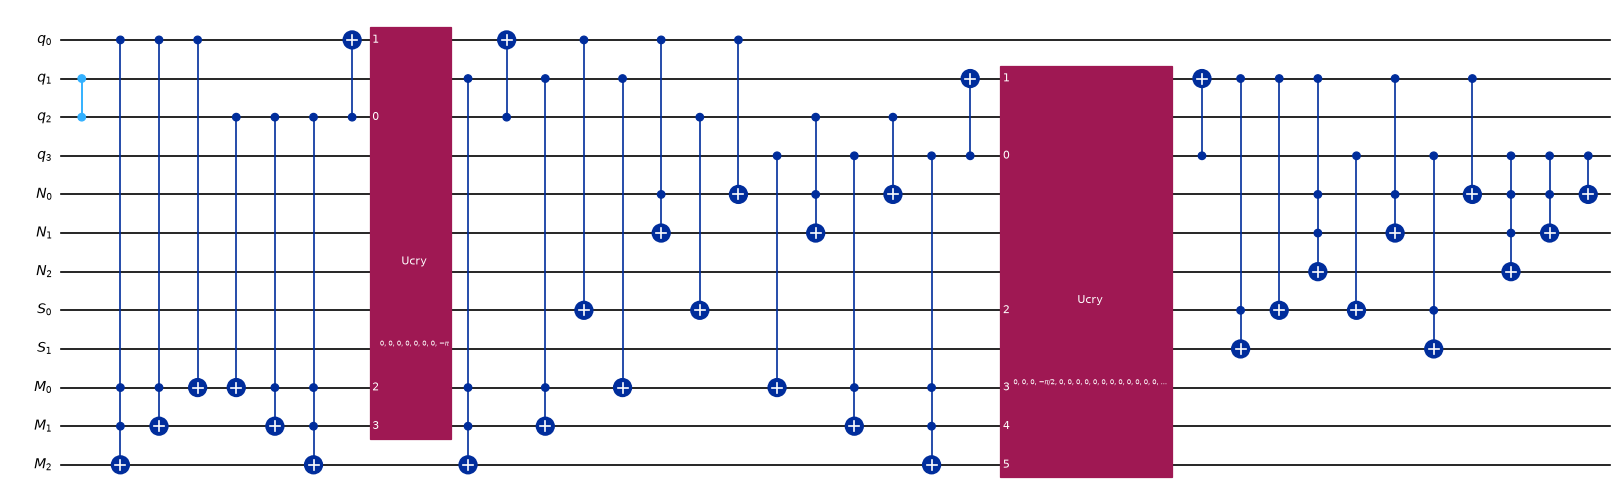

In [3]:
from qiskit.circuit import QuantumCircuit, QuantumRegister

norb = 2
gate = PaldusTransformJW(norb)
modes = QuantumRegister(2 * norb, name="q")
n_reg = QuantumRegister(gate.num_qubits_n, name="N")
s_reg = QuantumRegister(gate.num_qubits_s, name="S")
m_reg = QuantumRegister(gate.num_qubits_m, name="M")
circuit = QuantumCircuit(modes, n_reg, s_reg, m_reg)
circuit.append(gate, [*modes, *n_reg, *s_reg, *m_reg])

circuit.decompose().draw("mpl", scale=0.6, fold=-1)

## Measuring the total spin of a state

After the transform, the total spin of a state can be measured directly on the $S$ register. The following code cell applies the transform to a Slater determinant with two spin alpha electrons and one spin beta electron, using random orbitals for each spin. This state is a superposition of a doublet ($S = 1/2$) and a quartet ($S = 3/2$). The probabilities of the outcomes of the $S$ register reproduce the expectation value of $S^2$ computed by `ffsim.spin_square`.

In [4]:
norb = 3
nelec = (2, 1)
rng = np.random.default_rng(1234)
orbital_rotation = (
    ffsim.random.random_unitary(norb, seed=rng),
    ffsim.random.random_unitary(norb, seed=rng),
)
vec = ffsim.slater_determinant(norb, ([0, 1], [0]), orbital_rotation=orbital_rotation)

probs: dict[int, float] = {}
for (_, two_s, _, _), amplitude in paldus_transform(vec, norb, nelec).items():
    probs[two_s] = probs.get(two_s, 0.0) + abs(amplitude) ** 2
for two_s, prob in sorted(probs.items()):
    print(f"P(S = {two_s}/2) = {prob:.6f}")

s_squared = sum(prob * (two_s / 2) * (two_s / 2 + 1) for two_s, prob in probs.items())
print(f"<S^2> from the S register: {s_squared:.6f}")
print(f"<S^2> from ffsim.spin_square: {ffsim.spin_square(vec, norb, nelec):.6f}")

P(S = 1/2) = 0.838742
P(S = 3/2) = 0.161258
<S^2> from the S register: 1.233773
<S^2> from ffsim.spin_square: 1.233773


## CSF expansion of a ground state

Because the transform maps each GT state to a computational basis state, the output amplitudes of a state are its coefficients in the CSF basis. The eigenstates of a spin-free Hamiltonian have definite $S$, so their CSF expansions only involve step vectors with one value of $S$. The following code cell computes the ground state of a 3-site Fermi-Hubbard chain with three electrons and prints its CSF expansion. All of its CSFs have $S = 1/2$.

In [5]:
import scipy.sparse.linalg

norb = 3
nelec = (2, 1)
hamiltonian = ffsim.fermi_hubbard_1d(norb, tunneling=1.0, interaction=4.0)
linop = ffsim.linear_operator(hamiltonian, norb=norb, nelec=nelec)
_, eigenvectors = scipy.sparse.linalg.eigsh(linop, k=1, which="SA")
vec = eigenvectors[:, 0]

amplitudes = paldus_transform(vec, norb, nelec)
# Fix the arbitrary global phase so that the largest coefficient is positive
largest = max(amplitudes.values(), key=abs)
phase = largest.conjugate() / abs(largest)
# Sort by magnitude, breaking ties between equal magnitudes by label
for (n, two_s, two_m, steps), amplitude in sorted(
    amplitudes.items(), key=lambda item: (-round(abs(item[1]), 8), item[0])
):
    print(f"N={n} 2S={two_s} 2M={two_m} d={steps}: {(phase * amplitude).real:+.6f}")

N=3 2S=1 2M=1 d=udu: +0.767501
N=3 2S=1 2M=1 d=uud: -0.443117
N=3 2S=1 2M=1 d=02u: +0.223607
N=3 2S=1 2M=1 d=20u: +0.223607
N=3 2S=1 2M=1 d=u02: -0.223607
N=3 2S=1 2M=1 d=u20: -0.223607
N=3 2S=1 2M=1 d=0u2: -0.085410
N=3 2S=1 2M=1 d=2u0: +0.085410


## Relation to the quantum Schur transform

The quantum Schur transform performs the analogous change of basis for $n$ spin-1/2 particles, such as qubits. It maps each Schur state $|S, M; Y\rangle$, obtained by coupling the spins one at a time with Clebsch-Gordan coefficients, to the basis state $|Y\rangle|2S\rangle|2M\rangle$. Here $Y$ is the Yamanouchi symbol, an $n$-bit string whose bit $i$ is 0 if coupling spin $i$ raises the total spin and 1 if it lowers it.

A Schur state is the GT state in which every orbital is singly occupied, with spin up and spin down in orbital $i$ corresponding to a spin alpha and spin beta electron, and the Yamanouchi bits 0 and 1 matching the steps `u` and `d`. As a result, on inputs with single occupancy, the Paldus transform acts as the Schur transform. The Schur transform circuit is the same cascade of Clebsch-Gordan transforms, but with one qubit per spin, no $N$ register, and no fermionic sign layer.

ffsim implements the Schur transform as `SchurTransform` in `ffsim.qiskit.nonconserving`. `SchurTransform(num_spins)` acts on `num_spins` qubits holding the spins, with $|0\rangle$ for spin up and $|1\rangle$ for spin down, followed by `num_qubits_s` qubits holding $2S$ and `num_qubits_m` qubits holding $2M$ in two's complement. On output, the spin qubits hold the Yamanouchi symbol.

The following code cell applies the Schur transform to the state $|{\uparrow}{\downarrow}{\uparrow}\rangle$ of 3 spins. It then applies the Paldus transform to the corresponding determinant, with spin alpha electrons in orbitals 0 and 2 and a spin beta electron in orbital 1. Creating these electrons in orbital order, as the GT states do, gives a sign of $-1$ relative to ffsim's determinant, which creates all spin alpha electrons first. The two transforms give the same amplitudes, with step vectors `uuu`, `udu`, and `uud` in place of the Yamanouchi symbols `000`, `010`, and `001`.

In [6]:
from ffsim.qiskit.nonconserving import SchurTransform

num_spins = 3
schur = SchurTransform(num_spins)
# Qubit i holds spin i, so this index is the state |up, down, up>
vec = np.zeros(1 << schur.num_qubits, dtype=complex)
vec[0b010] = 1
result = np.array(Statevector(vec).evolve(schur))

print("Schur transform:")
for index in np.flatnonzero(np.abs(result) > 1e-10):
    yamanouchi = "".join(str((index >> i) & 1) for i in range(num_spins))
    two_s = (index >> num_spins) & ((1 << schur.num_qubits_s) - 1)
    two_m = index >> (num_spins + schur.num_qubits_s)
    if two_m >= 1 << (schur.num_qubits_m - 1):
        two_m -= 1 << schur.num_qubits_m
    print(f"2S={two_s} 2M={two_m} Y={yamanouchi}: {result[index].real:+.6f}")

print("Paldus transform:")
norb = num_spins
nelec = (2, 1)
vec = -ffsim.slater_determinant(norb, ([0, 2], [1]))
for (n, two_s, two_m, steps), amplitude in paldus_transform(vec, norb, nelec).items():
    print(f"N={n} 2S={two_s} 2M={two_m} d={steps}: {amplitude.real:+.6f}")

Schur transform:
2S=1 2M=1 Y=010: +0.707107
2S=1 2M=1 Y=001: -0.408248
2S=3 2M=1 Y=000: +0.577350
Paldus transform:
N=3 2S=1 2M=1 d=udu: +0.707107
N=3 2S=1 2M=1 d=uud: -0.408248
N=3 2S=3 2M=1 d=uuu: +0.577350


## Gate count

The paper's circuit uses $O(\text{norb}^3)$ controlled Givens rotations. ffsim's implementation multiplexes the rotations for each orbital into a single uniformly controlled $R_y$ gate, controlled only on the bits of the $S$ and $M$ registers that can be nonzero at that point. The following code cell compiles the gate to CX and single-qubit gates for several numbers of orbitals. At these sizes the number of CX gates grows more slowly than $\text{norb}^3$, because lower-order terms still contribute a significant fraction.

In [7]:
from qiskit import transpile

print(f"{'norb':>4} {'qubits':>6} {'CX':>6} {'CX / norb^3':>11}")
for norb in [2, 4, 6, 8, 10, 12]:
    gate = PaldusTransformJW(norb)
    circuit = QuantumCircuit(gate.num_qubits)
    circuit.append(gate, range(gate.num_qubits))
    transpiled = transpile(circuit, basis_gates=["cx", "u"], optimization_level=1)
    cx = transpiled.count_ops().get("cx", 0)
    print(f"{norb:>4} {gate.num_qubits:>6} {cx:>6} {cx / norb**3:>11.1f}")

norb qubits     CX CX / norb^3
   2     12    179        22.4
   4     19    764        11.9
   6     23   1659         7.7
   8     30   3274         6.4
  10     34   6003         6.0
  12     38   8696         5.0
